In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Read original dataset from https://www.kaggle.com/datasets/taweilo/loan-approval-classification-data
dataset = pd.read_csv('original_loan_data.csv')

# Simplify dataset
dataset["applicant_id"] = np.arange(1, len(dataset) + 1) # add a unique identifier (will be used as primary key), the relationship between loans and applicants is 1:1
dataset = dataset.drop(columns=['loan_intent']) 
col_mapping = {
    'applicant_id': 'applicant_id',
    'person_age': 'age',
    'person_gender': 'gender',
    'person_education': 'education_level',
    'person_income': 'income',
    'person_emp_exp': 'years_work_experience',
    'person_home_ownership': 'owns_home',
    'loan_amnt': 'loan_amount',
    'loan_int_rate': 'loan_interest_rate',
    'loan_percent_income': 'loan_percent_income',
    'cb_person_cred_hist_length': 'credit_history_length_years',
    'credit_score': 'credit_score',
    'previous_loan_defaults_on_file': 'previous_loan_defaults', # previously didnt pay back loan
    'loan_status': 'loan_approved',
}
# dtypes
dataset = dataset.rename(columns=col_mapping)
dataset["age"] = dataset["age"].astype(int)
dataset["income"] = dataset["income"].astype(int)
dataset["credit_history_length_years"] = dataset["credit_history_length_years"].astype(int)
dataset["loan_amount"] = dataset["loan_amount"].astype(int)
dataset["loan_approved"] = dataset["loan_approved"].astype(bool)
dataset["owns_home"] = dataset["owns_home"].apply(lambda x: x in ["MORTGAGE", "OWN"]).astype(bool)
dataset["previous_loan_defaults"] = dataset["previous_loan_defaults"].apply(lambda x: x == "Yes").astype(bool)
display(dataset.dtypes)
dataset


age                              int64
gender                          object
education_level                 object
income                           int64
years_work_experience            int64
owns_home                         bool
loan_amount                      int64
loan_interest_rate             float64
loan_percent_income            float64
credit_history_length_years      int64
credit_score                     int64
previous_loan_defaults            bool
loan_approved                     bool
applicant_id                     int64
dtype: object

,age,gender,education_level,income,years_work_experience,owns_home,loan_amount,loan_interest_rate,loan_percent_income,credit_history_length_years,credit_score,previous_loan_defaults,loan_approved,applicant_id
0,22,female,Master,71948,0,False,35000,16.02,0.49,3,561,False,True,1
1,21,female,High School,12282,0,True,1000,11.14,0.08,2,504,True,False,2
2,25,female,High School,12438,3,True,5500,12.87,0.44,3,635,False,True,3
3,23,female,Bachelor,79753,0,False,35000,15.23,0.44,2,675,False,True,4
4,24,male,Master,66135,1,False,35000,14.27,0.53,4,586,False,True,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44995,27,male,Associate,47971,6,False,15000,15.66,0.31,3,645,False,True,44996
44996,37,female,Associate,65800,17,False,9000,14.07,0.14,11,621,False,True,44997
44997,33,male,Associate,56942,7,False,2771,10.02,0.05,10,668,False,True,44998
44998,29,male,Bachelor,33164,4,False,12000,13.23,0.36,6,604,False,True,44999


In [2]:
# Split into two tables to prepare for SQL

loan_applications_columns = [
 'applicant_id',
 'loan_amount',
 'loan_interest_rate',
 'loan_percent_income',
 'loan_approved',
]

applicant_columns = [
 'applicant_id',
 'age',
 'gender',
 'education_level',
 'income',
 'years_work_experience',
 'owns_home',
 'credit_history_length_years',
 'credit_score',
 'previous_loan_defaults',
]

loan_applications = dataset[loan_applications_columns].copy()
applicants = dataset[applicant_columns].copy()

loan_applications.to_csv('data/loan_applications.csv', index=False)
applicants.to_csv('data/applicants.csv', index=False)

display(loan_applications.head())
display(applicants.head())

,applicant_id,loan_amount,loan_interest_rate,loan_percent_income,loan_approved
0,1,35000,16.02,0.49,True
1,2,1000,11.14,0.08,False
2,3,5500,12.87,0.44,True
3,4,35000,15.23,0.44,True
4,5,35000,14.27,0.53,True


,applicant_id,age,gender,education_level,income,years_work_experience,owns_home,credit_history_length_years,credit_score,previous_loan_defaults
0,1,22,female,Master,71948,0,False,3,561,False
1,2,21,female,High School,12282,0,True,2,504,True
2,3,25,female,High School,12438,3,True,3,635,False
3,4,23,female,Bachelor,79753,0,False,2,675,False
4,5,24,male,Master,66135,1,False,4,586,False


## To sql...

In [3]:
import sqlite3

conn = sqlite3.connect('data/loan_dataset.db')
loan_applications.to_sql('loan_applications', conn, if_exists='replace', index=False)
applicants.to_sql('applicants', conn, if_exists='replace', index=False)
# Check if the data was loaded correctly

# check if join works
query = """
SELECT *
FROM loan_applications
JOIN applicants
ON loan_applications.applicant_id = applicants.applicant_id
"""
pd.read_sql_query(query, conn)

,applicant_id,loan_amount,loan_interest_rate,loan_percent_income,loan_approved,applicant_id,age,gender,education_level,income,years_work_experience,owns_home,credit_history_length_years,credit_score,previous_loan_defaults
0,1,35000,16.02,0.49,1,1,22,female,Master,71948,0,0,3,561,0
1,2,1000,11.14,0.08,0,2,21,female,High School,12282,0,1,2,504,1
2,3,5500,12.87,0.44,1,3,25,female,High School,12438,3,1,3,635,0
3,4,35000,15.23,0.44,1,4,23,female,Bachelor,79753,0,0,2,675,0
4,5,35000,14.27,0.53,1,5,24,male,Master,66135,1,0,4,586,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44995,44996,15000,15.66,0.31,1,44996,27,male,Associate,47971,6,0,3,645,0
44996,44997,9000,14.07,0.14,1,44997,37,female,Associate,65800,17,0,11,621,0
44997,44998,2771,10.02,0.05,1,44998,33,male,Associate,56942,7,0,10,668,0
44998,44999,12000,13.23,0.36,1,44999,29,male,Bachelor,33164,4,0,6,604,0


## Test if everything works

/tmp/ipykernel_236113/2721969282.py:28: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql_query(query, conn)


,applicant_id,loan_amount,loan_interest_rate,loan_percent_income,loan_approved,applicant_id,age,gender,education_level,income,years_work_experience,owns_home,credit_history_length_years,credit_score,previous_loan_defaults
0,1,35000,16.02,0.49,1,1,22,female,Master,71948,0,0,3,561,0
1,2,1000,11.14,0.08,0,2,21,female,High School,12282,0,1,2,504,1
2,3,5500,12.87,0.44,1,3,25,female,High School,12438,3,1,3,635,0
3,4,35000,15.23,0.44,1,4,23,female,Bachelor,79753,0,0,2,675,0
4,5,35000,14.27,0.53,1,5,24,male,Master,66135,1,0,4,586,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44995,44996,15000,15.66,0.31,1,44996,27,male,Associate,47971,6,0,3,645,0
44996,44997,9000,14.07,0.14,1,44997,37,female,Associate,65800,17,0,11,621,0
44997,44998,2771,10.02,0.05,1,44998,33,male,Associate,56942,7,0,10,668,0
44998,44999,12000,13.23,0.36,1,44999,29,male,Bachelor,33164,4,0,6,604,0


,loan_amount,loan_interest_rate,loan_percent_income,age,income,years_work_experience,owns_home,credit_history_length_years,credit_score,previous_loan_defaults
0,35000,16.02,0.49,22,71948,0,0,3,561,0
1,1000,11.14,0.08,21,12282,0,1,2,504,1
2,5500,12.87,0.44,25,12438,3,1,3,635,0
3,35000,15.23,0.44,23,79753,0,0,2,675,0
4,35000,14.27,0.53,24,66135,1,0,4,586,0


0    1
1    0
2    1
3    1
4    1
Name: loan_approved, dtype: int64

(31500, 10) (13500, 10) (31500,) (13500,)
              precision    recall  f1-score   support

           0       0.77      1.00      0.87     10421
           1       0.00      0.00      0.00      3079

    accuracy                           0.77     13500
   macro avg       0.39      0.50      0.44     13500
weighted avg       0.60      0.77      0.67     13500

              precision    recall  f1-score   support

           0       0.93      0.96      0.95     10421
           1       0.86      0.76      0.81      3079

    accuracy                           0.92     13500
   macro avg       0.90      0.86      0.88     13500
weighted avg       0.91      0.92      0.91     13500



<Axes: xlabel='None', ylabel='None'>

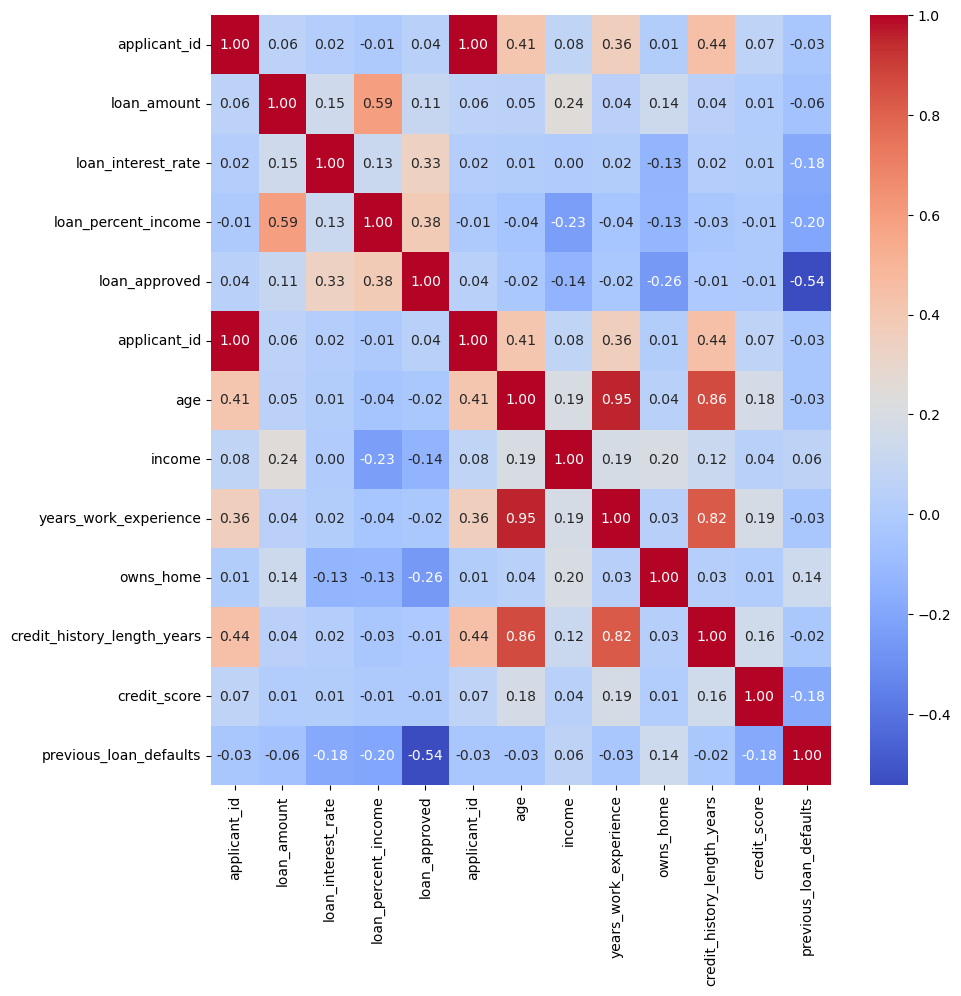

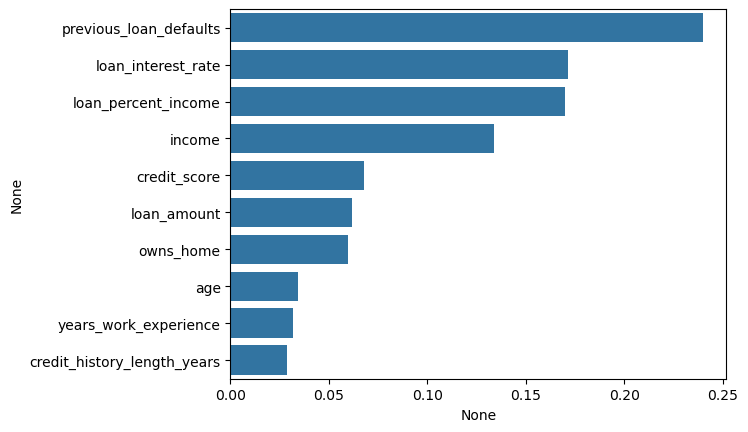

In [ ]:
# baseline majority classifier
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
import psycopg2

# conn = sqlite3.connect('data/loan_dataset.db')

conn = psycopg2.connect(
    dbname="postgres",
    user="postgres",
    password="passpass",
    host="localhost",
    port="5432"
)

query = """
SELECT *
FROM loan_applications
JOIN applicants
ON loan_applications.applicant_id = applicants.applicant_id
"""
df = pd.read_sql_query(query, conn)
display(df)

# Take a look at correlation
corr = df.drop(columns=['gender', 'education_level']).corr()
fig, ax = plt.subplots(figsize=(10, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', ax=ax)

# predictive...
X = df.drop(columns=['loan_approved', 'applicant_id', 'gender', 'education_level'])
y = df['loan_approved']
display(X.head(), y.head())

# train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1, shuffle=True)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

# baseline
dummy_clf = DummyClassifier(strategy="most_frequent")
dummy_clf.fit(X_train, y_train)
y_pred = dummy_clf.predict(X_test)
print(classification_report(y_test, y_pred, zero_division=0))

# random forest
rf = RandomForestClassifier(random_state=1)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)
print(classification_report(y_test, y_pred, zero_division=0))

# feature importance
feat = rf.feature_importances_
feat = pd.Series(feat, index=X.columns)
feat = feat.sort_values(ascending=False)
fig, ax = plt.subplots()
sns.barplot(x=feat, y=feat.index, ax=ax)